In [75]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterGrid
from sklearn.calibration import calibration_curve

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

RANDOM_STATE = 42
RUTA_DATOS = "../data/solicitudes_hmda.csv"
UMBRAL_OPERATIVO = None
MODELO_GANADOR = "M3_Gradient_Boosting"

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

In [77]:
def formatear_matriz_con_porcentajes(matriz):
    """
    Genera las etiquetas de texto para cada celda de la matriz de confusión
    incluyendo el conteo absoluto formateado y su porcentaje sobre el total.
    """
    total = np.sum(matriz)
    etiquetas = np.empty_like(matriz, dtype=object)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            conteo = matriz[i, j]
            pct = (conteo / total) * 100.0
            etiquetas[i, j] = f"{conteo:,}\n({pct:.1f}%)"
    return etiquetas


def graficar_analisis_operativo_detallado(y_real, prob_pred, matriz, umbral_corte, nombre_mod, etiqueta_periodo, sufijo_archivo):
    """
    Genera los dos paneles adicionales de diagnóstico operativo:
    1) Curva ROC con punto operativo + Curva Precision-Recall (PR-AUC).
    2) Matriz de Confusión con porcentajes + Curva de Compromiso Sensibilidad vs. VPP y F1 según umbral.
    """
    # 1. CURVA ROC Y CURVA PRECISION-RECALL
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

    # 1A. Curva ROC con Punto Operativo
    fpr, tpr, _ = roc_curve(y_real, prob_pred)
    auc_val = roc_auc_score(y_real, prob_pred)
    fpr_op = matriz[0, 1] / (matriz[0, 0] + matriz[0, 1])
    tpr_op = matriz[1, 1] / (matriz[1, 0] + matriz[1, 1])

    axes[0].plot(fpr, tpr, color="darkblue", lw=2.2, label=f"{nombre_mod} (AUC = {auc_val:.3f})")
    axes[0].plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle="--", label="Azar (AUC = 0.500)")
    axes[0].plot(fpr_op, tpr_op, "ro", markersize=8, label=f"Punto operativo p*={umbral_corte:.3f}")
    axes[0].set_xlim([0.0, 1.0])
    axes[0].set_ylim([0.0, 1.05])
    axes[0].set_xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
    axes[0].set_ylabel("Tasa de Verdaderos Positivos (Sensibilidad)")
    axes[0].set_title(f"Curva ROC - {nombre_mod} ({etiqueta_periodo})")
    axes[0].legend(loc="lower right")

    # 1B. Curva Precision-Recall con Punto Operativo
    prec_curve, rec_curve, _ = precision_recall_curve(y_real, prob_pred)
    pr_auc = average_precision_score(y_real, prob_pred)
    prevalencia = y_real.mean()
    vpp_op = matriz[1, 1] / max((matriz[0, 1] + matriz[1, 1]), 1)

    axes[1].plot(rec_curve, prec_curve, color="teal", lw=2.2, label=f"{nombre_mod} (PR-AUC = {pr_auc:.3f})")
    axes[1].axhline(prevalencia, color="gray", lw=1.5, linestyle="--", label=f"Referencia Trivial ({prevalencia*100:.1f}%)")
    axes[1].plot(tpr_op, vpp_op, "ro", markersize=8, label=f"Punto operativo p*={umbral_corte:.3f}")
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel("Sensibilidad (Recall)")
    axes[1].set_ylabel("Valor Predictivo Positivo (VPP / Precisión)")
    axes[1].set_title("Curva Precision-Recall (Sensible a Baja Prevalencia)")
    axes[1].legend(loc="upper right")

    plt.tight_layout()
    plt.savefig(f"roc_pr_operativo_{sufijo_archivo}.png", dpi=300)
    plt.show()

    # 2. MATRIZ Y TRADE OFF UMBRAL
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

    # 2A. Matriz de Confusión
    etiquetas_mat = formatear_matriz_con_porcentajes(matriz)
    sns.heatmap(
        matriz, annot=etiquetas_mat, fmt="", cmap="Blues", cbar=False, ax=axes[0],
        xticklabels=["Pred: Aprobado (0)", "Pred: Rechazo (1)"],
        yticklabels=["Real: Aprobado (0)", "Real: Rechazo (1)"]
    )
    axes[0].set_title(f"Matriz de Confusión Operativa (Umbral p* = {umbral_corte:.3f})")
    axes[0].set_ylabel("")
    axes[0].set_xlabel("")

    # 2B. Compromiso Sensibilidad vs. VPP y F1-Score (trade off según umbral)
    umbrales_grid = np.linspace(0.01, 0.30, 60)
    sens_lista, vpp_lista, f1_lista = [], [], []

    for u in umbrales_grid:
        pred_u = (prob_pred >= u).astype(int)
        sens_lista.append(recall_score(y_real, pred_u, zero_division=0))
        vpp_lista.append(precision_score(y_real, pred_u, zero_division=0))
        f1_lista.append(f1_score(y_real, pred_u, zero_division=0))

    axes[1].plot(umbrales_grid, sens_lista, color="tab:blue", lw=2.2, label="Sensibilidad (Captura de rechazos)")
    axes[1].plot(umbrales_grid, vpp_lista, color="tab:orange", lw=2.2, label="VPP (Precisión en alarmas)")
    axes[1].plot(umbrales_grid, f1_lista, color="green", lw=2.0, linestyle=":", label="F1-Score")
    axes[1].axvline(umbral_corte, color="red", lw=1.8, linestyle="--", label=f"Umbral Elegido p*={umbral_corte:.3f}")
    axes[1].set_xlim([0.0, 0.31])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel("Umbral de Decisión (p*)")
    axes[1].set_ylabel("Métrica Operativa")
    axes[1].set_title("Compromiso Sensibilidad vs. VPP según Umbral")
    axes[1].legend(loc="center right")

    plt.tight_layout()
    plt.savefig(f"matriz_compromiso_umbral_{sufijo_archivo}.png", dpi=300)
    plt.show()


In [79]:
# =============================================================================
# 1. CARGA, FILTRADO POBLACIONAL Y ANALISIS DE VAR. (DATA LEEK)
# =============================================================================
def limpiar_dti(valor):
    """
    Convierte la variable mixta 'debt_to_income_ratio' a escala continua.
    Asigna puntos medios a los intervalos y transforma 'Exempt' o vacíos en NaN.
    """
    if pd.isna(valor) or str(valor).strip().lower() in ["exempt", "nan", ""]:
        return np.nan
    s = str(valor).strip()
    mapeo_rangos = {
        "<20%": 15.0,
        "20%-<30%": 25.0,
        "30%-<36%": 33.0,
        "50%-60%": 55.0,
        ">60%": 65.0
    }
    if s in mapeo_rangos:
        return mapeo_rangos[s]
    try:
        return float(s)
    except ValueError:
        return np.nan


def preparar_base_analitica(ruta_csv):
    """
    Carga el dataset, aplica el filtro poblacional de Colorado especifico para proyecto, elimina
    variables con fuga de información (AUS, motivos de rechazo y costos finales)
    y construye el predictor financiero Loan-to-Income (lti_ratio).
    """
    df = pd.read_csv(ruta_csv, low_memory=False)
    df.columns = df.columns.str.strip().str.lower()

    # 1.A Filtro de la población objetivo
    condicion_poblacion = (
        (df["loan_type"] == 1) &                        # Préstamo convencional
        (df["loan_purpose"] == 1) &                     # Compra de vivienda
        (df["lien_status"] == 1) &                      # Primera hipoteca
        (df["occupancy_type"] == 1) &                   # Residencia principal
        (df["total_units"] == 1) &                      # Vivienda de 1 unidad
        (df["construction_method"] == 1) &              # Construcción tradicional (site-built)
        (df["reverse_mortgage"] == 2) &                 # Excluir hipotecas inversas
        (df["open-end_line_of_credit"] == 2) &          # Excluir líneas de crédito
        (df["business_or_commercial_purpose"] == 2) &   # Excluir propósitos comerciales
        (df["action_taken"].isin([1, 2, 3]))            # Originado (1), aprobado no aceptado (2), rechazado (3)
    )
    base = df[condicion_poblacion].copy()
    # Una vez aplicado el filtro en iteraciones anteriores, se vió que el tamaño del dataset no cambiaba
    # por lo que se asume que la data ya venia filtrada desde antes. 

    # 1.B Variable respuesta (Y = 1 si fue rechazado, 0 si fue aprobado o emitido) y clave única
    base["y"] = (base["action_taken"] == 3).astype(int)
    base["id_solicitud"] = base["activity_year"].astype(str) + "_" + base["fila_fuente"].astype(str)

    # 1.C Conversión de tipos y analisis de variables
    cols_numericas_raw = ["income", "loan_amount", "property_value", "loan_term", "loan_to_value_ratio"]
    for col in cols_numericas_raw:
        base[col] = pd.to_numeric(base[col], errors="coerce")

    base["dti_numerico"] = base["debt_to_income_ratio"].apply(limpiar_dti)

    # Ratio Loan-to-Income (Monto solicitado sobre ingreso anual en dólares)
    base["lti_ratio"] = base["loan_amount"] / (base["income"] * 1000.0)
    base["lti_ratio"] = base["lti_ratio"].replace([np.inf, -np.inf], np.nan)

    # 1.D Selección limpieza de columnas (evitando data leek)
    num_cols = ["income", "loan_amount", "property_value", "loan_term", "loan_to_value_ratio", "dti_numerico", "lti_ratio"]
    cat_cols = ["lei", "county_code"]
    cols_control = ["id_solicitud", "activity_year", "fila_fuente", "y"]

    base_limpia = base[cols_control + num_cols + cat_cols].copy()

    # 1.E Partición (2019-2022) y Reserva de Prueba (2023)
    df_dev = base_limpia[base_limpia["activity_year"].between(2019, 2022)].reset_index(drop=True)
    df_test = base_limpia[base_limpia["activity_year"] == 2023].reset_index(drop=True)

    print("=================================================================")
    print("VERIFICACIÓN DE INTEGRIDAD POBLACIONAL")
    print("=================================================================")
    print(f"Desarrollo (2019-2022): {len(df_dev):,} filas | Rechazos: {df_dev['y'].sum():,} (Esperado: 16,156)")
    print(f"Prueba (2023):          {len(df_test):,} filas  | Rechazos: {df_test['y'].sum():,}  (Esperado: 2,829)\n")

    return df_dev, df_test, num_cols, cat_cols



In [81]:
# =============================================================================
# 2. ANÁLISIS EXPLORATORIO DE DATOS Y VISUALIZACIÓN
# =============================================================================
def ejecutar_eda(df_dev, num_cols):
    """
    Tablas resumen de valores faltantes, evolución temporal de rechazos,
    gráficos y análisis de heterogeneidad por institución (LEI).
    """
    print("=================================================================")
    print("ANÁLISIS EXPLORATORIO EN DESARROLLO (2019-2022)")
    print("=================================================================")

    # 2.A Resumen de valores nulos
    resumen_nulos = pd.DataFrame({
        "Variable": df_dev.columns,
        "Nulos": df_dev.isna().sum().values,
        "Pct_Nulos (%)": (df_dev.isna().mean() * 100).round(2).values
    }).sort_values("Pct_Nulos (%)", ascending=False).reset_index(drop=True)
    print("--- Tabla 1: Valores Faltantes (2019-2022) ---")
    print(resumen_nulos[resumen_nulos["Nulos"] > 0].to_string(index=False))

    # 2.B Evolución temporal de solicitudes y rechazos
    stats_tiempo = df_dev.groupby("activity_year").agg(
        Total_Solicitudes=("y", "count"),
        Rechazos=("y", "sum"),
        Tasa_Rechazo_Pct=("y", lambda x: (x.mean() * 100).round(2))
    ).reset_index()
    print("\n--- Tabla 2: Evolución Anual de Solicitudes y Rechazos ---")
    print(stats_tiempo.to_string(index=False))

    fig, ax1 = plt.subplots(figsize=(8, 4.2))
    ax1.bar(stats_tiempo["activity_year"].astype(str), stats_tiempo["Total_Solicitudes"],
            color="steelblue", alpha=0.65, width=0.45, label="Total Solicitudes")
    ax1.set_ylabel("Volumen de Solicitudes", color="steelblue")
    ax1.set_xlabel("Año de Actividad")

    ax2 = ax1.twinx()
    ax2.plot(stats_tiempo["activity_year"].astype(str), stats_tiempo["Tasa_Rechazo_Pct"],
             color="firebrick", marker="o", linewidth=2.5, label="Tasa de Rechazo (%)")
    ax2.set_ylabel("Tasa de Rechazo (%)", color="firebrick")
    ax2.set_ylim(0, max(stats_tiempo["Tasa_Rechazo_Pct"]) * 1.4)
    plt.title("Evolución Temporal: Volumen y Tasa de Rechazo (2019-2022)")
    plt.savefig("eda_evolucion_temporal.png", dpi=300)
    plt.show()

    # 2.C Separabilidad de predictores clave (Boxplots)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    vars_graficar = [
        ("dti_numerico", "Carga Financiera - DTI (%)", (0, 70)),
        ("loan_to_value_ratio", "Apalancamiento - LTV (%)", (0, 130)),
        ("lti_ratio", "Ratio Préstamo/Ingreso - LTI (veces)", (0, 10))
    ]
    for idx, (col, titulo, ylim) in enumerate(vars_graficar):
        sns.boxplot(data=df_dev, x="y", y=col, hue="y", ax=axes[idx], palette="Set2", legend=False)
        axes[idx].set_ylim(ylim)
        axes[idx].set_xticks([0, 1])
        axes[idx].set_xticklabels(["Aprobado (0)", "Rechazado (1)"])
        axes[idx].set_xlabel("")
        axes[idx].set_ylabel(titulo)
        axes[idx].set_title(titulo)

    plt.suptitle("Separabilidad de Indicadores Financieros según Decisión Hipotecaria", y=1.02)
    plt.savefig("eda_separabilidad_financiera.png", dpi=300)
    plt.show()

    # 2.D Heterogeneidad institucional (lei)
    top_lei = df_dev["lei"].value_counts().head(15).index
    lei_stats = df_dev[df_dev["lei"].isin(top_lei)].groupby("lei").agg(
        Volumen=("y", "count"),
        Tasa_Rechazo_Pct=("y", lambda x: (x.mean() * 100).round(2))
    ).sort_values("Volumen", ascending=False).reset_index()

    plt.figure(figsize=(10, 4.2))
    sns.barplot(data=lei_stats, x="lei", y="Tasa_Rechazo_Pct", color="teal")
    plt.axhline(df_dev["y"].mean() * 100, color="red", linestyle="--", label="Prevalencia Media Global")
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Tasa de Rechazo (%)")
    plt.xlabel("Identificador de Institución Financiera (LEI)")
    plt.title("Heterogeneidad Institucional: Tasa de Rechazo en los 15 Principales Prestamistas")
    plt.legend()
    plt.savefig("eda_heterogeneidad_lei.png", dpi=300)
    plt.show()


In [83]:
# =============================================================================
# 3. TRANSFORMADOR (TARGET ENCODING) Y ARQUITECTURA DE PIPELINES
# =============================================================================
class TargetEncoderTemporal(BaseEstimator, TransformerMixin):
    """
    Transformador compatible con scikit-learn Pipeline que codifica variables
    categóricas (LEI, county_code) usando la tasa histórica de rechazo de
    entrenamiento. Imputa categorías nuevas o nulas con la prevalencia global.
    """
    def __init__(self):
        self.tasas_por_columna_ = {}
        self.tasa_global_ = 0.0
        self.columnas_ = []

    def fit(self, X, y):
        X_df = pd.DataFrame(X).copy()
        y_ser = pd.Series(y).reset_index(drop=True)
        X_df = X_df.reset_index(drop=True)

        self.columnas_ = list(X_df.columns)
        self.tasa_global_ = float(y_ser.mean())
        self.tasas_por_columna_ = {}

        for col in self.columnas_:
            tasas = y_ser.groupby(X_df[col]).mean().to_dict()
            self.tasas_por_columna_[col] = tasas
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        X_out = pd.DataFrame(index=X_df.index)

        for col in self.columnas_:
            mapa = self.tasas_por_columna_.get(col, {})
            X_out[col] = X_df[col].map(mapa).fillna(self.tasa_global_).astype(float)
        return X_out.values

    def get_feature_names_out(self, input_features=None):
        cols = input_features if input_features is not None else self.columnas_
        return np.array([f"{c}_codificado" for c in cols])


def construir_pipelines_y_grillas(num_cols, cat_cols):
    """
    Construye un Pipeline unificado para M1 (Regresión Logística), M2 (Árbol de Decisión)
    y M3 (Gradient Boosting), junto con sus grillas de hiperparámetros (<20 configs).
    """
    preprocesador = ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), num_cols),
            ("cat", Pipeline([
                ("target_enc", TargetEncoderTemporal()),
                ("scaler", StandardScaler())
            ]), cat_cols)
        ]
    )

    modelos_base = {
        "M1_Logistica_Ridge": Pipeline([
            ("prep", preprocesador),
            ("clf", LogisticRegression(penalty="l2", solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE))
        ]),
        "M2_Arbol_Decision": Pipeline([
            ("prep", preprocesador),
            ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))
        ]),
        "M3_Gradient_Boosting": Pipeline([
            ("prep", preprocesador),
            ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE))
        ])
    }

    grillas = {
        "M1_Logistica_Ridge": list(ParameterGrid({
            "clf__C": [0.001, 0.01, 0.1, 1.0, 10.0]
        })),
        "M2_Arbol_Decision": list(ParameterGrid({
            "clf__max_depth": [4, 6, 8, 10],
            "clf__min_samples_leaf": [50, 100, 250, 500]
        })),
        "M3_Gradient_Boosting": list(ParameterGrid({
            "clf__n_estimators": [50, 100],
            "clf__learning_rate": [0.05, 0.1],
            "clf__max_depth": [3, 5]
        }))
    }

    return modelos_base, grillas


In [85]:
# ===================================================
# 4. VALIDACIÓN TEMPORAL Y OPTIMIZACIÓN INTERNA
# =====================================================
def ejecutar_validacion_temporal(df_dev, num_cols, cat_cols, modelos_base, grillas, umbral_fijo=None):
    """
    Ejecuta modelos para 2020, 2021 y 2022.
    Métricas, curvas ROC, matrices de confusión
    """
    años_validacion = [2020, 2021, 2022]
    features_totales = num_cols + [f"{c}_codificado" for c in cat_cols]

    registro_metricas = []
    curvas_roc_2022 = {}
    matrices_2022 = {}
    mejores_configs_2022 = {}

    for año in años_validacion:
        print(f"\n{'='*70}")
        print(f"PARTICIÓN TEMPORAL: VALIDANDO EL AÑO {año} (Entrenamiento < {año})")
        print(f"{'='*70}")

        train_df = df_dev[df_dev["activity_year"] < año].reset_index(drop=True)
        val_df = df_dev[df_dev["activity_year"] == año].reset_index(drop=True)

        X_tr, y_tr = train_df[num_cols + cat_cols], train_df["y"]
        X_va, y_va = val_df[num_cols + cat_cols], val_df["y"]

        tasa_global_tr = y_tr.mean()
        p_base = np.full(shape=len(y_va), fill_value=tasa_global_tr)
        ll_base = log_loss(y_va, p_base)
        bs_base = brier_score_loss(y_va, p_base)

        umbral_corte = umbral_fijo if umbral_fijo is not None else tasa_global_tr

        registro_metricas.append({
            "Año": año,
            "Modelo": "0_Referencia_Historica",
            "Log_Loss": ll_base,
            "Delta_LL": 0.0,
            "Brier_Score": bs_base,
            "AUC_ROC": 0.5000,
            "Sensibilidad": 0.0,
            "VPP_Precision": 0.0
        })

        corte_int = int(len(X_tr) * 0.8)
        X_tr_in, y_tr_in = X_tr.iloc[:corte_int], y_tr.iloc[:corte_int]
        X_va_in, y_va_in = X_tr.iloc[corte_int:], y_tr.iloc[corte_int:]

        for nombre_mod, pipe in modelos_base.items():
            mejor_auc_int = -1.0
            mejor_config = None

            for config in grillas[nombre_mod]:
                pipe.set_params(**config)
                pipe.fit(X_tr_in, y_tr_in)
                prob_in = pipe.predict_proba(X_va_in)[:, 1]
                auc_in = roc_auc_score(y_va_in, prob_in)
                if auc_in > mejor_auc_int:
                    mejor_auc_int = auc_in
                    mejor_config = config

            pipe.set_params(**mejor_config)
            pipe.fit(X_tr, y_tr)

            prob_va = pipe.predict_proba(X_va)[:, 1]
            pred_clase = (prob_va >= umbral_corte).astype(int)

            ll_mod = log_loss(y_va, prob_va)
            bs_mod = brier_score_loss(y_va, prob_va)
            auc_mod = roc_auc_score(y_va, prob_va)
            sens = recall_score(y_va, pred_clase, zero_division=0)
            vpp = precision_score(y_va, pred_clase, zero_division=0)
            matriz = confusion_matrix(y_va, pred_clase)

            registro_metricas.append({
                "Año": año,
                "Modelo": nombre_mod,
                "Log_Loss": ll_mod,
                "Delta_LL": ll_mod - ll_base,
                "Brier_Score": bs_mod,
                "AUC_ROC": auc_mod,
                "Sensibilidad": sens,
                "VPP_Precision": vpp
            })

            print(f"\n>>> Modelo: {nombre_mod}")
            print(f"  Mejor Configuración : {mejor_config} (AUC interno: {mejor_auc_int:.4f})")
            print(f"  Log Loss Referencia : {ll_base:.4f}")
            print(f"  Log Loss Modelo     : {ll_mod:.4f} (Δ LL: {ll_mod - ll_base:+.4f}) | Brier: {bs_mod:.4f} | AUC ROC: {auc_mod:.4f}")
            print(f"  Métricas de Clasificación (Umbral = {umbral_corte:.4f} | Prevalencia Real = {y_va.mean():.4f}):")
            print(f"    Sensibilidad (Recall) : {sens:.4f}")
            print(f"    VPP (Precisión)       : {vpp:.4f}")
            print(f"    Matriz de Confusión   :\n{matriz}")

            clf_entrenado = pipe.named_steps["clf"]
            if hasattr(clf_entrenado, "coef_"):
                pesos = clf_entrenado.coef_[0]
                tipo_imp = "Coeficiente Estandarizado"
                orden = np.argsort(np.abs(pesos))[::-1]
            else:
                pesos = clf_entrenado.feature_importances_
                tipo_imp = "Importancia Gini"
                orden = np.argsort(pesos)[::-1]

            print(f"  Ranking de Predictores ({tipo_imp}):")
            for idx in orden:
                print(f"    - {features_totales[idx]:22s}: {pesos[idx]:+.4f}")

            if año == 2022:
                fpr, tpr, _ = roc_curve(y_va, prob_va)
                curvas_roc_2022[nombre_mod] = (fpr, tpr, auc_mod)
                matrices_2022[nombre_mod] = (matriz, umbral_corte, y_va.values, prob_va)
                mejores_configs_2022[nombre_mod] = mejor_config

    return pd.DataFrame(registro_metricas), curvas_roc_2022, matrices_2022, mejores_configs_2022



In [87]:
# =============================================================================
# 5. REPORTE ESTADÍSTICO Y GRÁFICOS (2020-2022)
# =============================================================================
def generar_reporte_desarrollo(df_resultados, curvas_roc_2022, matrices_2022):
    """
    Imprime la tabla comparativa promedio del 2020 hasta 2022 y grafica las matrices de
    Confusión (M1 vs M3), las Curvas ROC superpuestas y los
    paneles operativos detallados para M3 en 2022.
    """
    print(f"\n{'='*75}")
    print("RESUMEN PROMEDIO DE DESEMPEÑO EN DESARROLLO (VALIDACIÓN 2020-2022)")
    print(f"{'='*75}")

    cols_resumen = ["Log_Loss", "Delta_LL", "Brier_Score", "AUC_ROC", "Sensibilidad", "VPP_Precision"]
    tabla_promedio = (
        df_resultados.groupby("Modelo")[cols_resumen]
        .mean()
        .sort_values("Log_Loss")
        .round(4)
    )
    print(tabla_promedio.to_string())

    # 5.A Grafico de Matrices de Confusión con Porcentajes (M1 vs M3 en 2022)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    modelos_graficar_mat = ["M1_Logistica_Ridge", "M3_Gradient_Boosting"]

    for ax, nom_mod in zip(axes, modelos_graficar_mat):
        matriz, umb, _, _ = matrices_2022[nom_mod]
        etiquetas_mat = formatear_matriz_con_porcentajes(matriz)
        sns.heatmap(
            matriz, annot=etiquetas_mat, fmt="", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Pred: Aprobado (0)", "Pred: Rechazado (1)"],
            yticklabels=["Real: Aprobado (0)", "Real: Rechazado (1)"]
        )
        ax.set_title(f"Matriz de Confusión 2022 - {nom_mod}\n(Umbral = {umb:.4f})")
        ax.set_ylabel("Valor Real")
        ax.set_xlabel("Predicción del Modelo")

    plt.tight_layout()
    plt.savefig("comparativa_matrices_confusion_2022.png", dpi=300)
    plt.show()

    # 5.B Gráfico Comparativo de Curvas ROC de M1, M2 y M3 en el 2022
    plt.figure(figsize=(8, 6))
    colores = {
        "M1_Logistica_Ridge": "darkorange",
        "M2_Arbol_Decision": "royalblue",
        "M3_Gradient_Boosting": "darkgreen"
    }

    for nom_mod, (fpr, tpr, auc_val) in curvas_roc_2022.items():
        plt.plot(fpr, tpr, lw=2.2, color=colores.get(nom_mod, "black"),
                 label=f"{nom_mod} (AUC = {auc_val:.4f})")

    plt.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Azar / Referencia (AUC = 0.5000)")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
    plt.ylabel("Tasa de Verdaderos Positivos (Sensibilidad)")
    plt.title("Comparación de Curvas ROC - Validación Temporal 2022")
    plt.legend(loc="lower right")
    plt.savefig("comparativa_curvas_roc_2022.png", dpi=300)
    plt.show()

    # 5.C ROC + PR y Matriz + tradeoff por umbral en 2022
    if MODELO_GANADOR in matrices_2022:
        mat_22, umb_22, y_22, prob_22 = matrices_2022[MODELO_GANADOR]
        graficar_analisis_operativo_detallado(
            y_real=y_22,
            prob_pred=prob_22,
            matriz=mat_22,
            umbral_corte=umb_22,
            nombre_mod="M3 Gradient Boosting",
            etiqueta_periodo="Colorado 2022",
            sufijo_archivo="2022"
        )



In [89]:
# =========================================================
# 6. EVALUACIÓN DE RESERVA AÑO 2023 Y GRÁFICOS FINALES
# =========================================================
def evaluar_reserva_prueba_2023(df_dev, df_test, num_cols, cat_cols, modelos_base, mejores_configs_2022, nombre_ganador="M3_Gradient_Boosting", umbral_fijo=None):
    """
    Entrena el modelo con el 100% de la base de desarrollo (2019-2022)
    usando los hiperparámetros óptimos validados, evalúa por única vez sobre la
    reserva de prueba 2023 y genera el panel diagnóstico de 4 gráficos más los
    paneles operativos detallados.
    """
    print(f"\n{'='*75}")
    print(f"EVALUACIÓN DEFINITIVA EN RESERVA DE PRUEBA (AÑO 2023) - {nombre_ganador}")
    print(f"{'='*75}")

    features_totales = num_cols + [f"{c}_codificado" for c in cat_cols]
    X_dev, y_dev = df_dev[num_cols + cat_cols], df_dev["y"]
    X_test, y_test = df_test[num_cols + cat_cols], df_test["y"]

    # 6.A Configuración óptima y ajustar en 2019-2022
    pipe_ganador = modelos_base[nombre_ganador]
    mejor_config = mejores_configs_2022[nombre_ganador]

    pipe_ganador.set_params(**mejor_config)
    pipe_ganador.fit(X_dev, y_dev)

    # 6.B Predicción sobre la reserva de prueba 2023
    tasa_global_dev = y_dev.mean()
    umbral_corte = umbral_fijo if umbral_fijo is not None else tasa_global_dev

    prob_test = pipe_ganador.predict_proba(X_test)[:, 1]
    pred_test = (prob_test >= umbral_corte).astype(int)

    # 6.C Cálculo de métricas fuera de muestra 2023
    p_base_test = np.full(shape=len(y_test), fill_value=tasa_global_dev)
    ll_base_test = log_loss(y_test, p_base_test)
    bs_base_test = brier_score_loss(y_test, p_base_test)

    ll_test = log_loss(y_test, prob_test)
    bs_test = brier_score_loss(y_test, prob_test)
    auc_test = roc_auc_score(y_test, prob_test)
    sens_test = recall_score(y_test, pred_test, zero_division=0)
    vpp_test = precision_score(y_test, pred_test, zero_division=0)
    matriz_test = confusion_matrix(y_test, pred_test)

    print(f"  Entrenamiento Final           : 2019-2022 ({len(df_dev):,} solicitudes)")
    print(f"  Evaluación Reserva de Prueba  : 2023 ({len(df_test):,} solicitudes | {y_test.sum():,} rechazos)")
    print(f"  Configuración Óptima Aplicada : {mejor_config}")
    print(f"  Log Loss Referencia (2023)    : {ll_base_test:.4f} | Brier Base: {bs_base_test:.4f}")
    print(f"  Log Loss Modelo (2023)        : {ll_test:.4f} (Δ LL: {ll_test - ll_base_test:+.4f}) | Brier Modelo: {bs_test:.4f}")
    print(f"  AUC ROC (2023)                : {auc_test:.4f}")
    print(f"  Métricas Operativas (Umbral = {umbral_corte:.4f} | Prevalencia Real 2023 = {y_test.mean():.4f}):")
    print(f"    Sensibilidad (Recall)       : {sens_test:.4f}")
    print(f"    VPP (Precisión)             : {vpp_test:.4f}")
    print(f"    Matriz de Confusión 2023    :\n{matriz_test}\n")

    # 6.D Panel Visual de Evaluación 2023
    fig, axes = plt.subplots(2, 2, figsize=(15, 11))

    # Gráfico A: Matriz de Confusión 2023
    etiquetas_mat_test = formatear_matriz_con_porcentajes(matriz_test)
    sns.heatmap(
        matriz_test, annot=etiquetas_mat_test, fmt="", cmap="Greens", cbar=False, ax=axes[0, 0],
        xticklabels=["Pred: Aprobado (0)", "Pred: Rechazado (1)"],
        yticklabels=["Real: Aprobado (0)", "Real: Rechazado (1)"]
    )
    axes[0, 0].set_title(f"A. Matriz de Confusión Reserva 2023\n({nombre_ganador} | Umbral = {umbral_corte:.4f})")
    axes[0, 0].set_ylabel("Valor Real (2023)")
    axes[0, 0].set_xlabel("Predicción del Modelo")

    # Gráfico B: Curva ROC 2023
    fpr_t, tpr_t, _ = roc_curve(y_test, prob_test)
    axes[0, 1].plot(fpr_t, tpr_t, color="darkgreen", lw=2.5, label=f"{nombre_ganador} (AUC = {auc_test:.4f})")
    axes[0, 1].plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Azar (AUC = 0.5000)")
    axes[0, 1].set_xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
    axes[0, 1].set_ylabel("Tasa de Verdaderos Positivos (Sensibilidad)")
    axes[0, 1].set_title("B. Curva ROC en Reserva de Prueba (2023)")
    axes[0, 1].legend(loc="lower right")

    # Gráfico C: Curva de Calibración Probabilística en 2023
    prob_true, prob_pred = calibration_curve(y_test, prob_test, n_bins=10, strategy="quantile")
    axes[1, 0].plot(prob_pred, prob_true, marker="o", linewidth=2, color="teal", label="Calibración M3 (Cuantiles)")
    axes[1, 0].plot([0, max(prob_true) * 1.1], [0, max(prob_true) * 1.1], linestyle="--", color="gray", label="Calibración Perfecta")
    axes[1, 0].set_xlabel("Probabilidad Media Predicha de Rechazo")
    axes[1, 0].set_ylabel("Fracción Real de Rechazos Observada (2023)")
    axes[1, 0].set_title("C. Curva de Calibración de Probabilidades (2023)")
    axes[1, 0].legend(loc="upper left")

    # Gráfico D: Importancia de Predictores en el Modelo Final (2019-2022)
    clf_final = pipe_ganador.named_steps["clf"]
    importancias = clf_final.feature_importances_ if hasattr(clf_final, "feature_importances_") else np.abs(clf_final.coef_[0])
    df_imp = pd.DataFrame({"Predictor": features_totales, "Importancia": importancias}).sort_values("Importancia", ascending=True)

    axes[1, 1].barh(df_imp["Predictor"], df_imp["Importancia"], color="steelblue", alpha=0.85)
    axes[1, 1].set_xlabel("Importancia Relativa (Gini)")
    axes[1, 1].set_title("D. Importancia de Variables (Modelo Entrenado 2019-2022)")

    plt.suptitle("Evaluación Final Fuera de Muestra: Reserva de Prueba Año 2023", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig("evaluacion_final_2023.png", dpi=300)
    plt.show()

    # 6.E Paneles Operativos Detallados para la Reserva de Prueba 2023
    graficar_analisis_operativo_detallado(
        y_real=y_test.values,
        prob_pred=prob_test,
        matriz=matriz_test,
        umbral_corte=umbral_corte,
        nombre_mod="M3 Gradient Boosting",
        etiqueta_periodo="Colorado 2023",
        sufijo_archivo="2023"
    )

    # Guardar tabla de predicciones individuales con clave única id_solicitud
    df_predicciones_2023 = pd.DataFrame({
        "id_solicitud": df_test["id_solicitud"],
        "activity_year": df_test["activity_year"],
        "y_real": y_test,
        "probabilidad_rechazo": prob_test.round(6),
        "prediccion_clase": pred_test
    })

    return df_predicciones_2023



VERIFICACIÓN DE INTEGRIDAD POBLACIONAL
Desarrollo (2019-2022): 310,131 filas | Rechazos: 16,156 (Esperado: 16,156)
Prueba (2023):          49,914 filas  | Rechazos: 2,829  (Esperado: 2,829)

ANÁLISIS EXPLORATORIO EN DESARROLLO (2019-2022)
--- Tabla 1: Valores Faltantes (2019-2022) ---
           Variable  Nulos  Pct_Nulos (%)
          lti_ratio   4024           1.30
             income   2965           0.96
loan_to_value_ratio   1934           0.62
       dti_numerico   1773           0.57
     property_value   1662           0.54
        county_code    649           0.21
          loan_term    359           0.12

--- Tabla 2: Evolución Anual de Solicitudes y Rechazos ---
 activity_year  Total_Solicitudes  Rechazos  Tasa_Rechazo_Pct
          2019              73518      4079              5.55
          2020              79446      4181              5.26
          2021              87583      4162              4.75
          2022              69584      3734              5.37


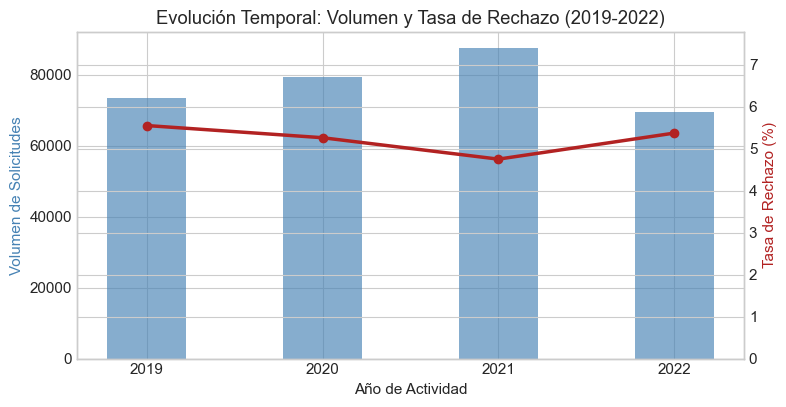

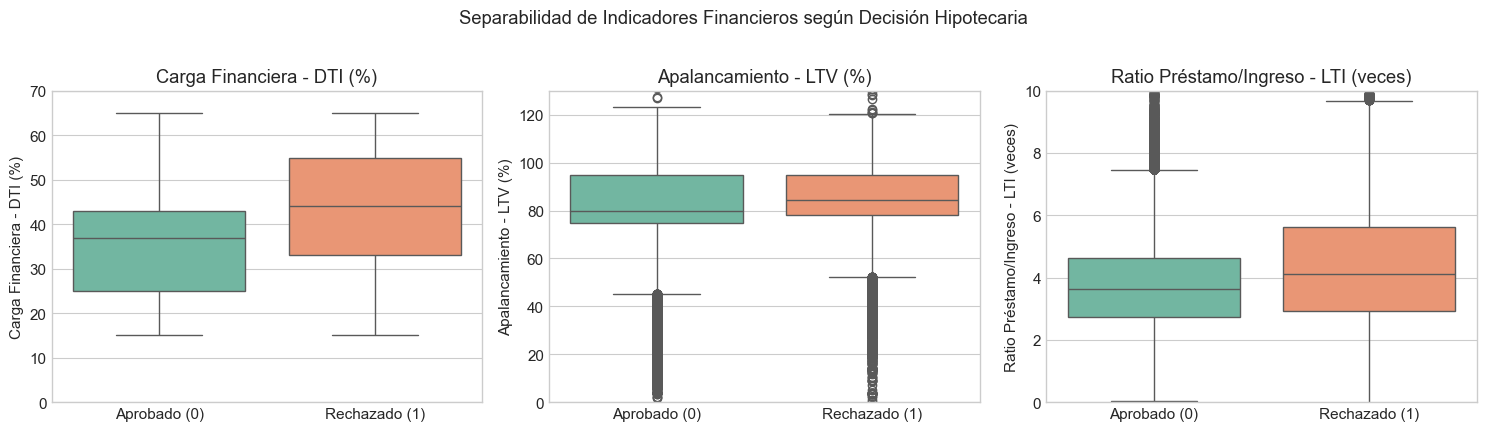

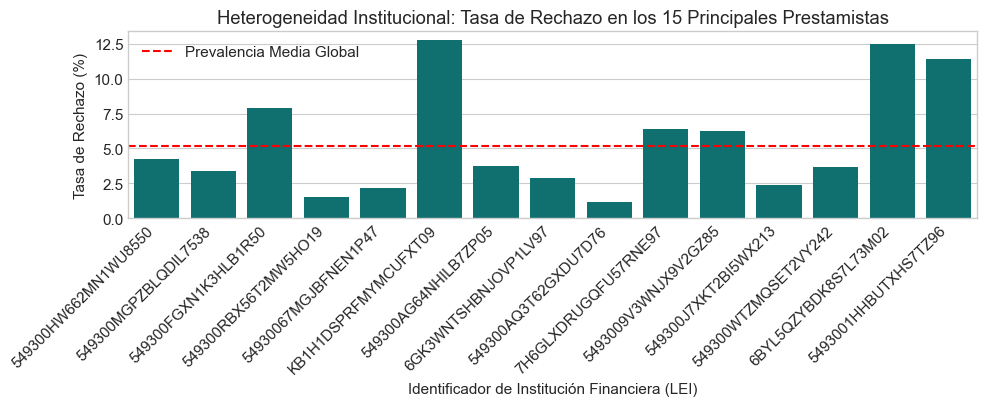


PARTICIÓN TEMPORAL: VALIDANDO EL AÑO 2020 (Entrenamiento < 2020)

>>> Modelo: M1_Logistica_Ridge
  Mejor Configuración : {'clf__C': 0.001} (AUC interno: 0.6412)
  Log Loss Referencia : 0.2063
  Log Loss Modelo     : 0.1773 (Δ LL: -0.0289) | Brier: 0.0446 | AUC ROC: 0.7601
  Métricas de Clasificación (Umbral = 0.0555 | Prevalencia Real = 0.0526):
    Sensibilidad (Recall) : 0.6477
    VPP (Precisión)       : 0.1358
    Matriz de Confusión   :
[[58032 17233]
 [ 1473  2708]]
  Ranking de Predictores (Coeficiente Estandarizado):
    - dti_numerico          : +0.5767
    - lei_codificado        : +0.5594
    - county_code_codificado: +0.1215
    - lti_ratio             : +0.1037
    - loan_to_value_ratio   : +0.0628
    - income                : +0.0435
    - loan_amount           : +0.0368
    - loan_term             : -0.0361
    - property_value        : +0.0312

>>> Modelo: M2_Arbol_Decision
  Mejor Configuración : {'clf__max_depth': 10, 'clf__min_samples_leaf': 500} (AUC interno: 0.67

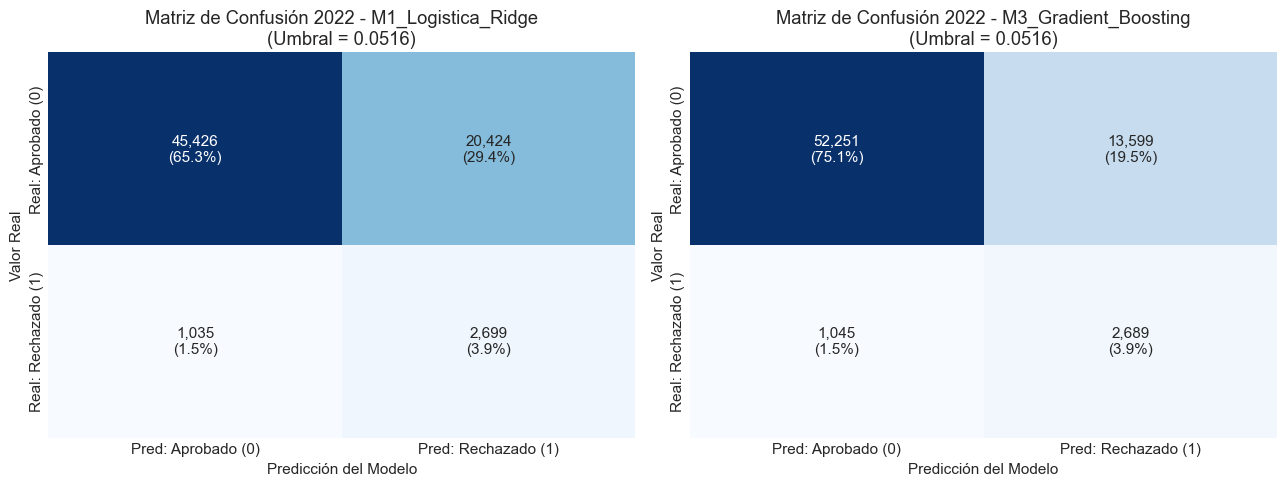

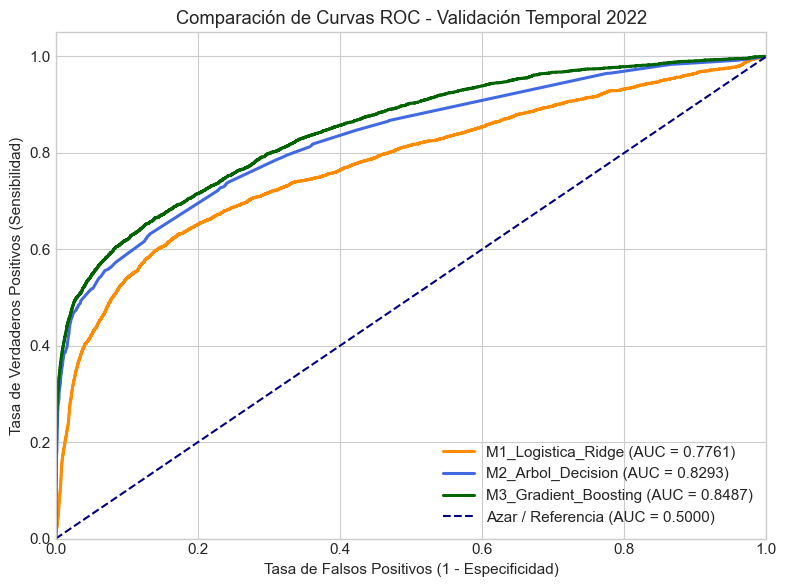

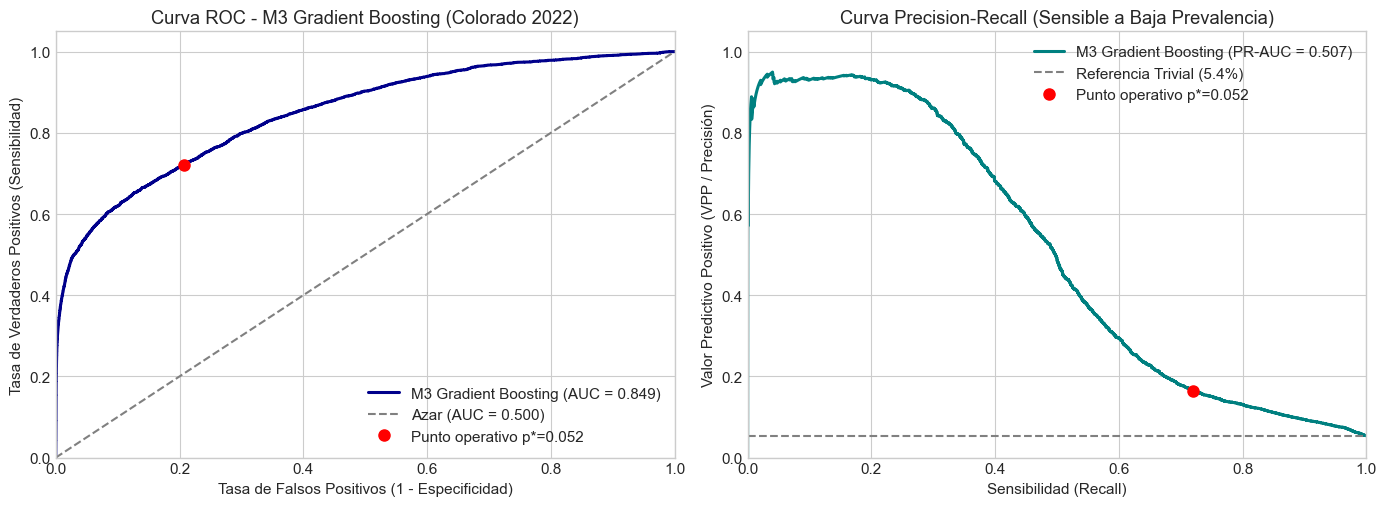

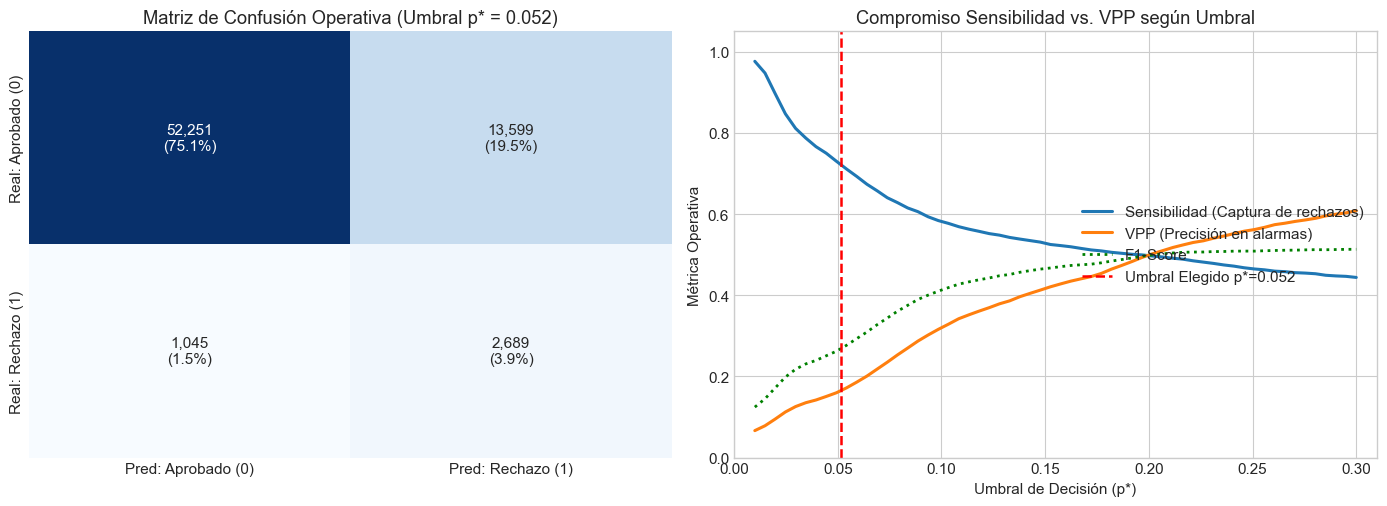


EVALUACIÓN DEFINITIVA EN RESERVA DE PRUEBA (AÑO 2023) - M3_Gradient_Boosting
  Entrenamiento Final           : 2019-2022 (310,131 solicitudes)
  Evaluación Reserva de Prueba  : 2023 (49,914 solicitudes | 2,829 rechazos)
  Configuración Óptima Aplicada : {'clf__learning_rate': 0.1, 'clf__max_depth': 5, 'clf__n_estimators': 100}
  Log Loss Referencia (2023)    : 0.2179 | Brier Base: 0.0535
  Log Loss Modelo (2023)        : 0.1534 (Δ LL: -0.0645) | Brier Modelo: 0.0385
  AUC ROC (2023)                : 0.8395
  Métricas Operativas (Umbral = 0.0521 | Prevalencia Real 2023 = 0.0567):
    Sensibilidad (Recall)       : 0.7151
    VPP (Precisión)             : 0.1765
    Matriz de Confusión 2023    :
[[37645  9440]
 [  806  2023]]



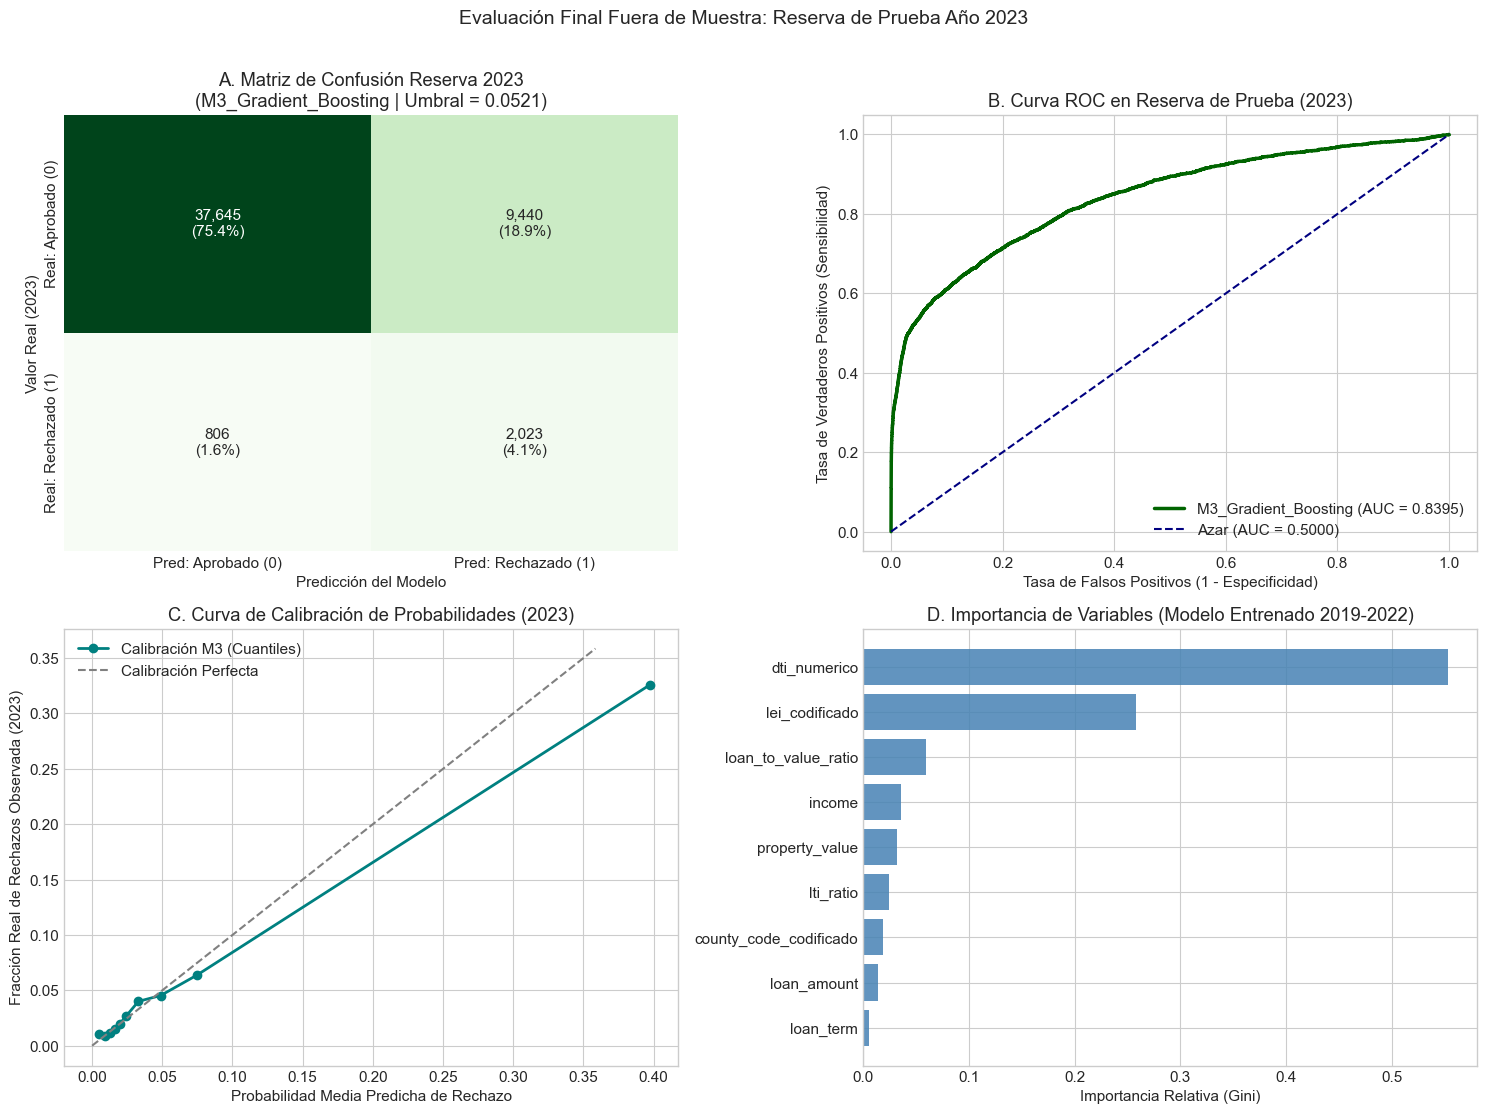

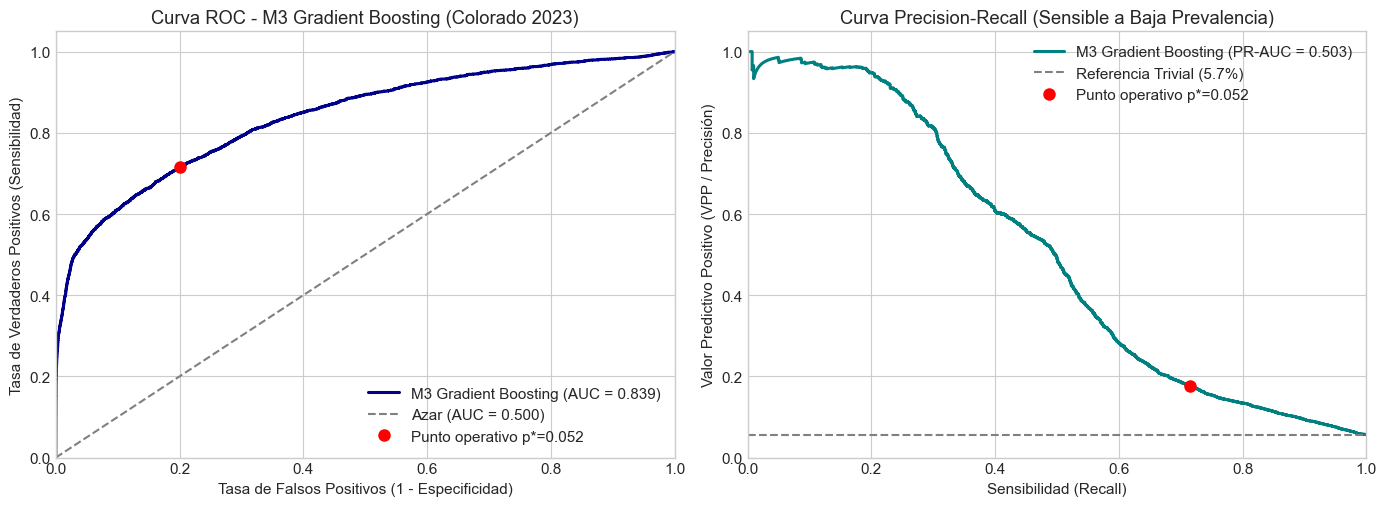

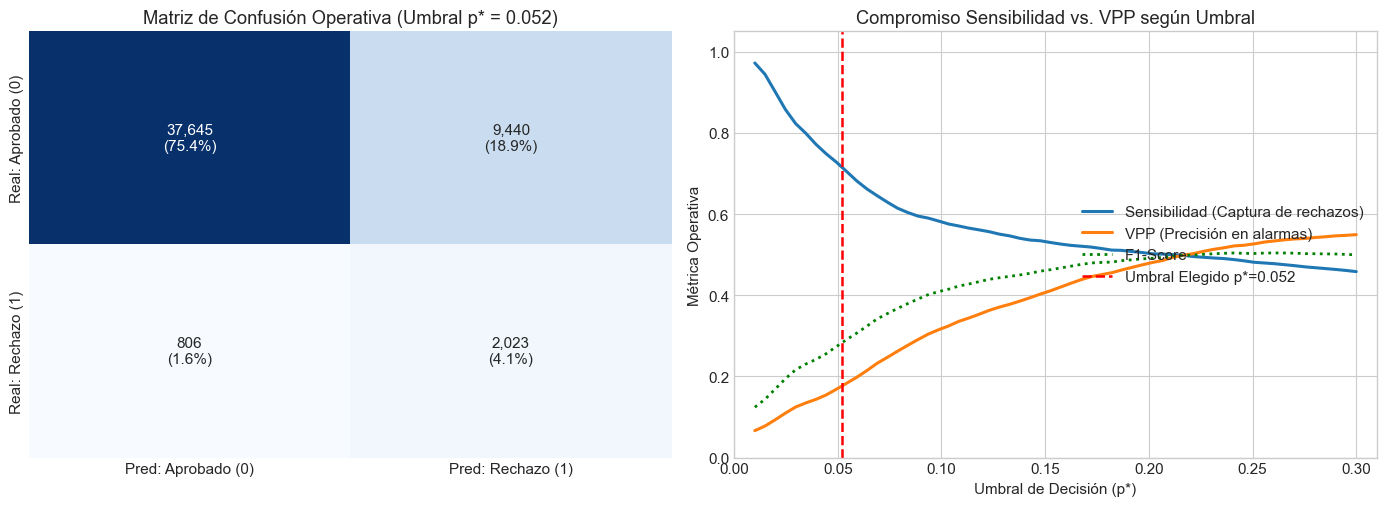

In [91]:
# ===================
# EJECUCIÓN PIPELINE
# ===================
if __name__ == "__main__":
    # 1. Preparación y filtrado de datos
    df_dev, df_test, num_cols, cat_cols = preparar_base_analitica(RUTA_DATOS)

    # 2. Análisis Exploratorio de Datos
    ejecutar_eda(df_dev, num_cols)

    # 3. Construcción de Pipelines modulares y grillas
    modelos_base, grillas = construir_pipelines_y_grillas(num_cols, cat_cols)

    # 4. Validación (2020, 2021, 2022)
    df_resultados, curvas_roc_2022, matrices_2022, mejores_configs_2022 = ejecutar_validacion_temporal(
        df_dev, num_cols, cat_cols, modelos_base, grillas, umbral_fijo=UMBRAL_OPERATIVO
    )

    # 5. Reporte Estadístico y Visualizaciones (2020, 2021, 2022)
    generar_reporte_desarrollo(df_resultados, curvas_roc_2022, matrices_2022)

    # 6. Evaluación Final sobre Reserva de Prueba (2023)
    df_predicciones_2023 = evaluar_reserva_prueba_2023(
        df_dev, df_test, num_cols, cat_cols, modelos_base, mejores_configs_2022,
        nombre_ganador=MODELO_GANADOR, umbral_fijo=UMBRAL_OPERATIVO
    )